# Exercise 2: Finetuning a Pretrained Model for Binary Text Classification

### 1. Cài đặt thư viện (transformers, datasets, evaluate) và kiểm tra GPU
Đã cài trong Terminal: `python -m pip install transformers datasets evaluate accelerate scikit-learn`.

In [7]:
import numpy as np
import torch
import evaluate
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer, set_seed)

set_seed(42)
print("GPU:", torch.cuda.is_available(), "-", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

GPU: False - CPU


### 2. Tải bộ dữ liệu phân loại văn bản 2 lớp (rotten_tomatoes)

In [8]:
dataset = load_dataset("cornell-movie-review-data/rotten_tomatoes")
print(dataset)
print("Ví dụ:", dataset["train"][0])
print("Nhãn:", dataset["train"].features["label"].names)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
})
Ví dụ: {'text': 'the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .', 'label': 1}
Nhãn: ['neg', 'pos']


### 3. Tải model và tokenizer đã huấn luyện sẵn
Cảnh báo *"Some weights ... newly initialized"* là bình thường: lớp phân loại cuối là lớp mới, sẽ được fine-tune.

In [9]:
model_name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1},
)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 270.97it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### 4. Tiền xử lý dữ liệu

In [10]:
def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

tokenized = dataset.map(tokenize_function, batched=True)

train_ds = tokenized["train"].shuffle(seed=42)   # toàn bộ 8.530 câu
val_ds = tokenized["validation"]                # theo dõi quá trình học
test_ds = tokenized["test"]                      # chỉ đánh giá ở bước cuối

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print("Train:", len(train_ds),
      "| Validation:", len(val_ds),
      "| Test:", len(test_ds))

Train: 8530 | Validation: 1066 | Test: 1066


### 5. Định nghĩa tham số huấn luyện

In [ ]:
accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "f1": f1.compute(predictions=preds, references=labels)["f1"],
    }

training_args = TrainingArguments(
    output_dir="results_ex2",
    eval_strategy="epoch",
    save_strategy="no",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_steps=50,
    fp16=torch.cuda.is_available(),   # GPU NVIDIA: dùng 16-bit cho nhanh
    report_to="none",
    seed=42,
)

### 6. Tạo Trainer và fine-tune model

In [12]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

before = trainer.evaluate()
print(f"VALIDATION trước fine-tune: accuracy = {before['eval_accuracy']:.2%}")

trainer.train()

Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.696840,0,0.451220,0.174894


VALIDATION trước fine-tune: accuracy = 45.12%


c:\Lab3_AI\Lap_Deep\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.395768,0.356864,0.839587,0.840037


TrainOutput(global_step=534, training_loss=0.42611098378785095, metrics={'train_runtime': 1177.7354, 'train_samples_per_second': 7.243, 'train_steps_per_second': 0.453, 'total_flos': 107742565677168.0, 'train_loss': 0.42611098378785095, 'epoch': 1.0})

### 7. Đánh giá model sau khi fine-tune

In [13]:
# Đánh giá model ở cuối epoch 3, không nạp lại checkpoint.
after = trainer.evaluate()
print(f"VALIDATION trước fine-tune: accuracy = {before['eval_accuracy']:.2%}")
print(f"VALIDATION sau fine-tune:   accuracy = {after['eval_accuracy']:.2%} | F1 = {after['eval_f1']:.2%}")

# Đánh giá test riêng sau khi hoàn tất huấn luyện.
test_metrics = trainer.evaluate(
    eval_dataset=test_ds,
    metric_key_prefix="test",
)
print(f"TEST: accuracy = {test_metrics['test_accuracy']:.2%} | F1 = {test_metrics['test_f1']:.2%}")

from transformers import pipeline
clf = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer)
for s in ["An absolute masterpiece with brilliant acting.",
          "Boring plot and terrible dialogue.",
          "Not bad at all!"]:
    r = clf(s)[0]
    print(f"{r['label']:8s} {r['score']:.2%} | {s}")

c:\Lab3_AI\Lap_Deep\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.395768,0.356864,1,0.839587,0.840037


VALIDATION trước fine-tune: accuracy = 45.12%
VALIDATION sau fine-tune:   accuracy = 83.96% | F1 = 84.00%


c:\Lab3_AI\Lap_Deep\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.395768,0.383397,1,0.835835,0.837209


TEST: accuracy = 83.58% | F1 = 83.72%
POSITIVE 97.78% | An absolute masterpiece with brilliant acting.
NEGATIVE 96.69% | Boring plot and terrible dialogue.
NEGATIVE 66.07% | Not bad at all!


### Biểu đồ training loss

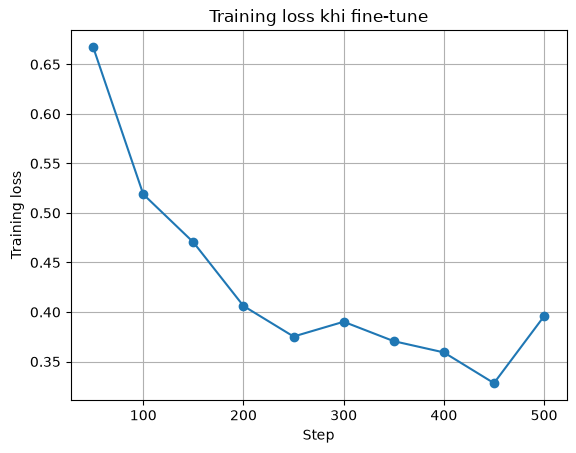

In [14]:
import matplotlib.pyplot as plt
logs = trainer.state.log_history
steps = [l["step"] for l in logs if "loss" in l]
losses = [l["loss"] for l in logs if "loss" in l]
plt.plot(steps, losses, marker="o")
plt.xlabel("Step"); plt.ylabel("Training loss"); plt.title("Training loss khi fine-tune")
plt.grid(True); plt.show()

### Nhận xét
- **Phân chia dữ liệu:** train dùng để cập nhật trọng số; validation dùng để theo dõi quá trình học; test dùng để đánh giá cuối cùng sau khi hoàn tất huấn luyện.
- **Trước và sau fine-tune:** so sánh accuracy trên cùng tập validation ở bước 7. Kết quả test được báo cáo riêng bằng accuracy và F1.
- **Model được đánh giá:** dùng model ở cuối epoch 3. Không lưu checkpoint và không tự động chọn lại model của epoch trước.
- **Overfitting:** đối chiếu training loss với validation loss theo từng epoch. Nếu training loss giảm nhưng validation loss tăng, đó là dấu hiệu overfitting.
- **Kết quả:** cần Restart Kernel và Run All để có số liệu cho phiên bản không checkpoint. Các output cũ đã được xóa để tránh nhầm kết quả.
